# Practice 2. NumPy & Pandas Foundations
**NumPy arrays, Pandas indexing, filtering, and initial EDA**

Author: Tomiris | KBTU, School of Information Technology and Engineering

## Task 1. NumPy

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

### 1.1 Creating a 2D array and inspecting its structure

In [3]:
# 2D array: 5 rows x 6 columns, e.g. exam scores of 5 students in 6 subjects
arr = np.random.randint(40, 101, size=(5, 6))
print(arr)

[[ 78  91  68  54  82  47]
 [100  60  78  97  58  62]
 [ 50  50  63  92  75  79]
 [ 63  42  61  92  41  63]
 [ 83  69  77  41  99  60]]


In [3]:
print("shape:", arr.shape)
print("ndim :", arr.ndim)
print("size :", arr.size)
print("dtype:", arr.dtype)

shape: (5, 6)
ndim : 2
size : 30
dtype: int64


### 1.2 Indexing and slicing

In [4]:
print("Element [2, 3]        :", arr[2, 3])
print("First row arr[0]      :", arr[0])
print("Last row arr[-1]      :", arr[-1])
print("Column 1 arr[:, 1]    :", arr[:, 1])
print("Rows 1-3, cols 2-4:\n", arr[1:4, 2:5])
print("Every 2nd row:\n", arr[::2])
print("Reversed columns of row 0:", arr[0, ::-1])

Element [2, 3]        : 92
First row arr[0]      : [78 91 68 54 82 47]
Last row arr[-1]      : [83 69 77 41 99 60]
Column 1 arr[:, 1]    : [91 60 50 42 69]
Rows 1-3, cols 2-4:
 [[78 97 58]
 [63 92 75]
 [61 92 41]]
Every 2nd row:
 [[78 91 68 54 82 47]
 [50 50 63 92 75 79]
 [83 69 77 41 99 60]]
Reversed columns of row 0: [47 82 54 68 91 78]


### 1.3 Basic statistics (whole array and along axes)

In [5]:
print("Whole array -> sum:", arr.sum(), "| mean:", arr.mean().round(2),
      "| median:", np.median(arr), "| std:", arr.std().round(2),
      "| min:", arr.min(), "| max:", arr.max())

Whole array -> sum: 2075 | mean: 69.17 | median: 65.5 | std: 17.46 | min: 41 | max: 100


### 1.4 axis=0 vs axis=1
`axis=0` aggregates **down the rows** (one result per column); `axis=1` aggregates **across the columns** (one result per row).

In [6]:
print("axis=0 (per column) mean:", arr.mean(axis=0).round(2))
print("axis=1 (per row)    mean:", arr.mean(axis=1).round(2))
print()
print("axis=0 (per column) max :", arr.max(axis=0))
print("axis=1 (per row)    max :", arr.max(axis=1))
print()
print("axis=0 sum:", arr.sum(axis=0), "-> shape", arr.sum(axis=0).shape)
print("axis=1 sum:", arr.sum(axis=1), "-> shape", arr.sum(axis=1).shape)

axis=0 (per column) mean: [74.8 62.4 69.4 75.2 71.  62.2]
axis=1 (per row)    mean: [70.   75.83 68.17 60.33 71.5 ]

axis=0 (per column) max : [100  91  78  97  99  79]
axis=1 (per row)    max : [ 91 100  92  92  99]

axis=0 sum: [374 312 347 376 355 311] -> shape (6,)
axis=1 sum: [420 455 409 362 429] -> shape (5,)


### 1.5 Vectorized operations (no Python loops)

In [6]:
print("arr + 5:\n", arr + 5)
print("\narr * 2:\n", arr * 2)
print("\nNormalised (0-1) scores:\n", ((arr - arr.min()) / (arr.max() - arr.min())).round(2))
print("\nBoolean mask arr >= 80:\n", arr >= 80)
print("\nNumber of scores >= 80:", (arr >= 80).sum())
print("Scores >= 80 only:", arr[arr >= 80])
# Broadcasting: subtract each column's mean from that column
print("\nCentered by column mean:\n", (arr - arr.mean(axis=0)).round(1))
# Replace values with np.where
print("\nPass/Fail (>=60):\n", np.where(arr >= 60, "Pass", "Fail"))

arr + 5:
 [[ 83  96  73  59  87  52]
 [105  65  83 102  63  67]
 [ 55  55  68  97  80  84]
 [ 68  47  66  97  46  68]
 [ 88  74  82  46 104  65]]

arr * 2:
 [[156 182 136 108 164  94]
 [200 120 156 194 116 124]
 [100 100 126 184 150 158]
 [126  84 122 184  82 126]
 [166 138 154  82 198 120]]

Normalised (0-1) scores:
 [[0.63 0.85 0.46 0.22 0.69 0.1 ]
 [1.   0.32 0.63 0.95 0.29 0.36]
 [0.15 0.15 0.37 0.86 0.58 0.64]
 [0.37 0.02 0.34 0.86 0.   0.37]
 [0.71 0.47 0.61 0.   0.98 0.32]]

Boolean mask arr >= 80:
 [[False  True False False  True False]
 [ True False False  True False False]
 [False False False  True False False]
 [False False False  True False False]
 [ True False False False  True False]]

Number of scores >= 80: 8
Scores >= 80 only: [ 91  82 100  97  92  92  83  99]

Centered by column mean:
 [[  3.2  28.6  -1.4 -21.2  11.  -15.2]
 [ 25.2  -2.4   8.6  21.8 -13.   -0.2]
 [-24.8 -12.4  -6.4  16.8   4.   16.8]
 [-11.8 -20.4  -8.4  16.8 -30.    0.8]
 [  8.2   6.6   7.6 -34.2  28

## Task 2. DataFrame
**Dataset:** Titanic passengers (seaborn-data, 891 rows × 15 columns), contains numerical and categorical variables and real missing values.

In [7]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
try:
    df = pd.read_csv(url)
except Exception:
    df = pd.read_csv("titanic.csv")   # local fallback
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [8]:
print("Shape (rows, columns):", df.shape)
print("Column names:", list(df.columns))

Shape (rows, columns): (891, 15)
Column names: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


In [11]:
df.dtypes

survived         int64
pclass           int64
sex                str
age            float64
sibsp            int64
parch            int64
fare           float64
embarked           str
class              str
who                str
adult_male        bool
deck               str
embark_town        str
alive              str
alone             bool
dtype: object

In [12]:
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nTotal missing cells:", df.isna().sum().sum())

Missing values per column:
age            177
embarked         2
deck           688
embark_town      2
dtype: int64



Total missing cells: 869


In [13]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [14]:
df.describe(exclude='number')

,sex,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891,889,891,891,891,203,889,891,891
unique,2,3,3,3,2,7,3,2,2
top,male,S,Third,man,True,C,Southampton,no,True
freq,577,644,491,537,537,59,644,549,537


**What does one row represent?** One row represents **one passenger** of the Titanic: his/her class, sex, age, family on board, ticket fare, port of embarkation and whether he/she survived.

**Variables**
- Numerical: `age`, `fare`, `sibsp`, `parch`
- Categorical / binary: `survived`, `pclass`, `sex`, `embarked`, `class`, `who`, `adult_male`, `deck`, `embark_town`, `alive`, `alone`

## Task 3. Indexing (`loc` vs `iloc`)
`loc` selects by **labels** (index labels and column names, slice end is inclusive); `iloc` selects by **integer position** (slice end is exclusive).

In [15]:
df.iloc[0]   # first row by position

survived                 0
pclass                   3
sex                   male
age                   22.0
sibsp                    1
parch                    0
fare                  7.25
embarked                 S
class                Third
who                    man
adult_male            True
deck                   NaN
embark_town    Southampton
alive                   no
alone                False
Name: 0, dtype: object

In [16]:
df.iloc[0:5, 0:4]   # first 5 rows, first 4 columns (end excluded)

,survived,pclass,sex,age
0,0,3,male,22.0
1,1,1,female,38.0
2,1,3,female,26.0
3,1,1,female,35.0
4,0,3,male,35.0


In [10]:
df.loc[0:5, ['sex', 'age', 'fare']]   # rows labelled 0..5 (end INCLUDED), columns by name

,sex,age,fare
0,male,22.0,7.2500
1,female,38.0,71.2833
2,female,26.0,7.9250
3,female,35.0,53.1000
4,male,35.0,8.0500
5,male,NaN,8.4583


In [11]:
print("iloc  value (row 3, col 3):", df.iloc[3, 3])
print("loc   value (row 3, 'age')  :", df.loc[3, 'age'])

iloc  value (row 3, col 3): 35.0
loc   value (row 3, 'age')  : 35.0


In [12]:
df.loc[:, 'sex':'fare'].head()   # column range by labels

,sex,age,sibsp,parch,fare
0,male,22.0,1,0,7.2500
1,female,38.0,1,0,71.2833
2,female,26.0,0,0,7.9250
3,female,35.0,1,0,53.1000
4,male,35.0,0,0,8.0500


In [13]:
df.iloc[[0, 10, 20, 30], [1, 2, 6]]   # specific rows and columns by position lists

,pclass,sex,fare
0,3,male,7.2500
10,3,female,16.7000
20,2,male,26.0000
30,1,male,27.7208


In [15]:
# Difference loc vs iloc: slice end
print("iloc[0:3] ->", len(df.iloc[0:3]), "rows")
print("loc[0:3]  ->", len(df.loc[0:3]), "rows")

iloc[0:3] -> 3 rows
loc[0:3]  -> 4 rows


In [14]:
# Difference becomes clear after re-indexing: set a non-default index
df_s = df.sort_values('fare', ascending=False)
print(df_s[['sex','age','fare']].head(3))
print("\niloc[0] -> top row by position:")
print(df_s.iloc[0][['sex','age','fare']].to_dict())
print("\nloc[0]  -> row with LABEL 0 (the first passenger in original file):")
print(df_s.loc[0][['sex','age','fare']].to_dict())

        sex   age      fare
679    male  36.0  512.3292
258  female  35.0  512.3292
737    male  35.0  512.3292

iloc[0] -> top row by position:
{'sex': 'male', 'age': 36.0, 'fare': 512.3292}

loc[0]  -> row with LABEL 0 (the first passenger in original file):
{'sex': 'male', 'age': 22.0, 'fare': 7.25}


## Task 4. Filtering

**Q1 (numerical condition):** Which passengers paid a fare higher than 100?

In [16]:
q1 = df[df['fare'] > 100]
print(len(q1), "passengers")
q1[['sex', 'age', 'pclass', 'fare', 'survived']].head(10)

53 passengers


,sex,age,pclass,fare,survived
27,male,19.0,1,263.0000,0
31,female,NaN,1,146.5208,1
88,female,23.0,1,263.0000,1
118,male,24.0,1,247.5208,0
195,female,58.0,1,146.5208,1
215,female,31.0,1,113.2750,1
258,female,35.0,1,512.3292,1
268,female,58.0,1,153.4625,1
269,female,35.0,1,135.6333,1
297,female,2.0,1,151.5500,0


**Q2 (categorical condition):** Which passengers embarked in Cherbourg?

In [17]:
q2 = df[df['embark_town'] == 'Cherbourg']
print(len(q2), "passengers | survival rate:", q2['survived'].mean().round(3))
q2[['sex', 'age', 'pclass', 'embark_town', 'survived']].head(10)

168 passengers | survival rate: 0.554


,sex,age,pclass,embark_town,survived
1,female,38.0,1,Cherbourg,1
9,female,14.0,2,Cherbourg,1
19,female,NaN,3,Cherbourg,1
26,male,NaN,3,Cherbourg,0
30,male,40.0,1,Cherbourg,0
31,female,NaN,1,Cherbourg,1
34,male,28.0,1,Cherbourg,0
36,male,NaN,3,Cherbourg,1
39,female,14.0,3,Cherbourg,1
42,male,NaN,3,Cherbourg,0


**Q3 (multiple conditions):** Which women in first class survived?

In [18]:
q3 = df[(df['sex'] == 'female') & (df['pclass'] == 1) & (df['survived'] == 1)]
print(len(q3), "passengers")
q3[['sex', 'age', 'pclass', 'fare', 'survived']].head(10)

91 passengers


,sex,age,pclass,fare,survived
1,female,38.0,1,71.2833,1
3,female,35.0,1,53.1000,1
11,female,58.0,1,26.5500,1
31,female,NaN,1,146.5208,1
52,female,49.0,1,76.7292,1
61,female,38.0,1,80.0000,1
88,female,23.0,1,263.0000,1
136,female,19.0,1,26.2833,1
151,female,22.0,1,66.6000,1
166,female,NaN,1,55.0000,1


**Q4 (calculated value):** Which passengers are older than the average age and paid more than the median fare?

In [19]:
mean_age = df['age'].mean()
median_fare = df['fare'].median()
print(f"mean age = {mean_age:.2f}, median fare = {median_fare:.2f}")
q4 = df[(df['age'] > mean_age) & (df['fare'] > median_fare)]
print(len(q4), "passengers | survival rate:", q4['survived'].mean().round(3))
q4[['sex', 'age', 'pclass', 'fare', 'survived']].head(10)

mean age = 29.70, median fare = 14.45
196 passengers | survival rate: 0.541


,sex,age,pclass,fare,survived
1,female,38.0,1,71.2833,1
3,female,35.0,1,53.1000,1
6,male,54.0,1,51.8625,0
11,female,58.0,1,26.5500,1
13,male,39.0,3,31.2750,0
15,female,55.0,2,16.0000,1
18,female,31.0,3,18.0000,0
20,male,35.0,2,26.0000,0
25,female,38.0,3,31.3875,1
30,male,40.0,1,27.7208,0


## Task 5. Initial EDA

### 5.1 Data quality

In [20]:
missing = pd.DataFrame({'missing': df.isna().sum(), 'percent': (df.isna().mean()*100).round(2)})
missing[missing['missing'] > 0].sort_values('missing', ascending=False)

,missing,percent
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22


In [21]:
print("Duplicated rows:", df.duplicated().sum())
print("Rows after dropping duplicates:", len(df.drop_duplicates()))

Duplicated rows: 107
Rows after dropping duplicates: 784


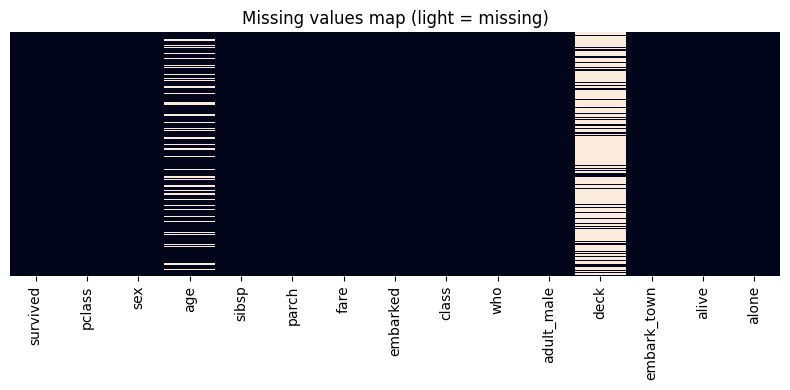

In [22]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, ax=ax)
ax.set_title("Missing values map (light = missing)")
plt.tight_layout(); plt.show()

### 5.2 Categorical variables - `value_counts()`

In [23]:
for col in ['survived', 'sex', 'pclass', 'embark_town', 'who']:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False))
    print()

--- survived ---
survived
0    549
1    342
Name: count, dtype: int64

--- sex ---
sex
male      577
female    314
Name: count, dtype: int64

--- pclass ---
pclass
3    491
1    216
2    184
Name: count, dtype: int64

--- embark_town ---
embark_town
Southampton    644
Cherbourg      168
Queenstown      77
NaN              2
Name: count, dtype: int64

--- who ---
who
man      537
woman    271
child     83
Name: count, dtype: int64



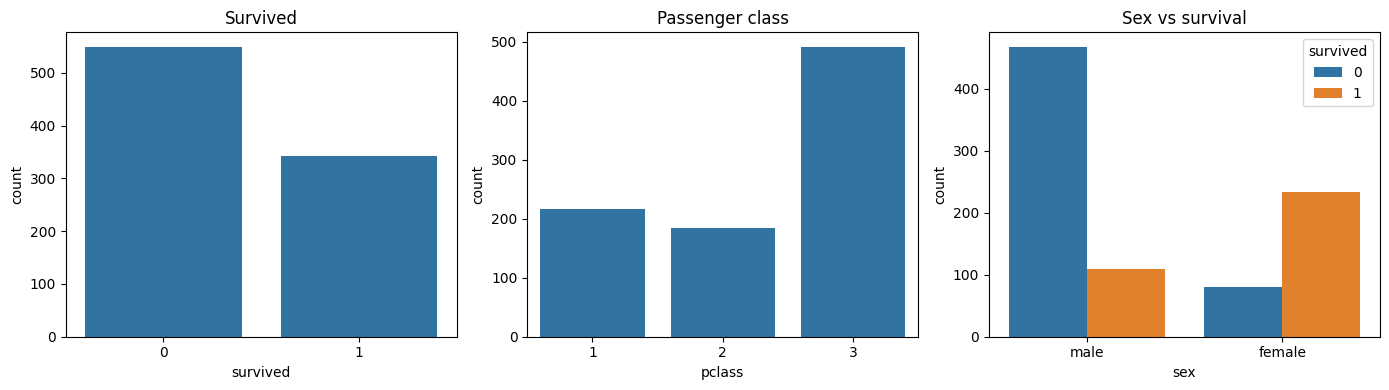

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.countplot(data=df, x='survived', ax=axes[0]); axes[0].set_title('Survived')
sns.countplot(data=df, x='pclass', ax=axes[1]); axes[1].set_title('Passenger class')
sns.countplot(data=df, x='sex', hue='survived', ax=axes[2]); axes[2].set_title('Sex vs survival')
plt.tight_layout(); plt.show()

In [32]:
print("Survival rate by sex (%):")
print((df.groupby('sex')['survived'].mean()*100).round(1))
print("\nSurvival rate by class (%):")
print((df.groupby('pclass')['survived'].mean()*100).round(1))

Survival rate by sex (%):
sex
female    74.2
male      18.9
Name: survived, dtype: float64

Survival rate by class (%):
pclass
1    63.0
2    47.3
3    24.2
Name: survived, dtype: float64


### 5.3 Numerical variables - distributions

In [25]:
num_cols = ['age', 'fare', 'sibsp', 'parch']
df[num_cols].describe().round(2)

,age,fare,sibsp,parch
count,714.00,891.00,891.00,891.00
mean,29.70,32.20,0.52,0.38
std,14.53,49.69,1.10,0.81
min,0.42,0.00,0.00,0.00
25%,20.12,7.91,0.00,0.00
50%,28.00,14.45,0.00,0.00
75%,38.00,31.00,1.00,0.00
max,80.00,512.33,8.00,6.00


In [26]:
print("Skewness:")
print(df[num_cols].skew().round(2))

Skewness:
age      0.39
fare     4.79
sibsp    3.70
parch    2.75
dtype: float64


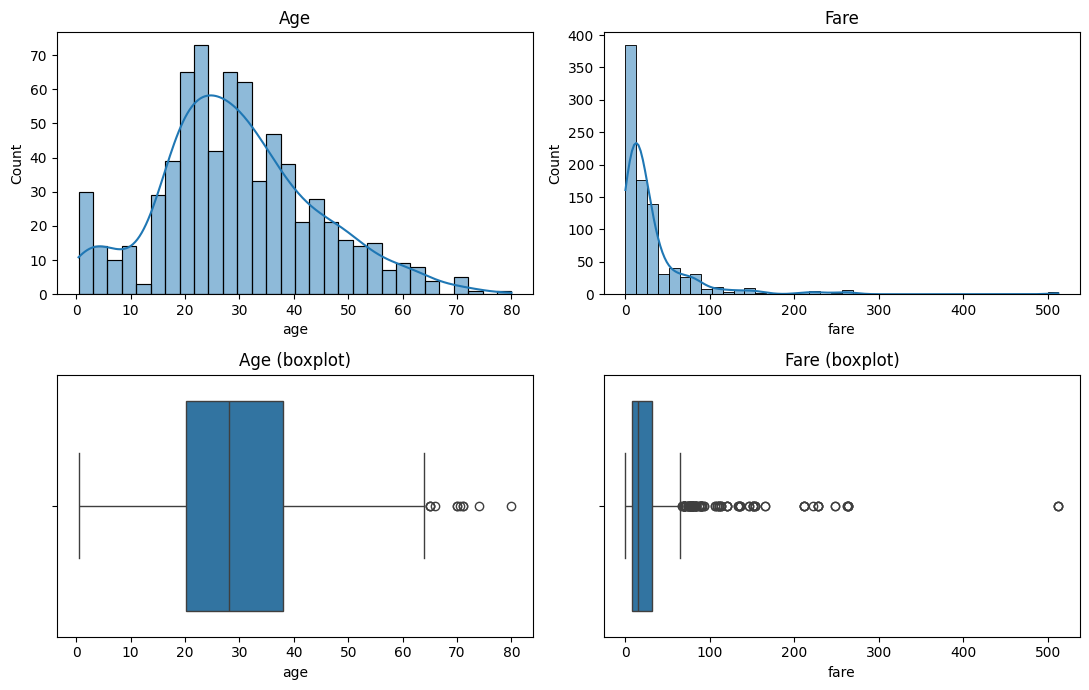

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
sns.histplot(df['age'].dropna(), bins=30, kde=True, ax=axes[0,0]); axes[0,0].set_title('Age')
sns.histplot(df['fare'], bins=40, kde=True, ax=axes[0,1]); axes[0,1].set_title('Fare')
sns.boxplot(x=df['age'], ax=axes[1,0]); axes[1,0].set_title('Age (boxplot)')
sns.boxplot(x=df['fare'], ax=axes[1,1]); axes[1,1].set_title('Fare (boxplot)')
plt.tight_layout(); plt.show()

### 5.4 Relationships between numerical features

In [28]:
corr = df[['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']].corr().round(2)
corr

,survived,pclass,age,sibsp,parch,fare
survived,1.00,-0.34,-0.08,-0.04,0.08,0.26
pclass,-0.34,1.00,-0.37,0.08,0.02,-0.55
age,-0.08,-0.37,1.00,-0.31,-0.19,0.10
sibsp,-0.04,0.08,-0.31,1.00,0.41,0.16
parch,0.08,0.02,-0.19,0.41,1.00,0.22
fare,0.26,-0.55,0.10,0.16,0.22,1.00


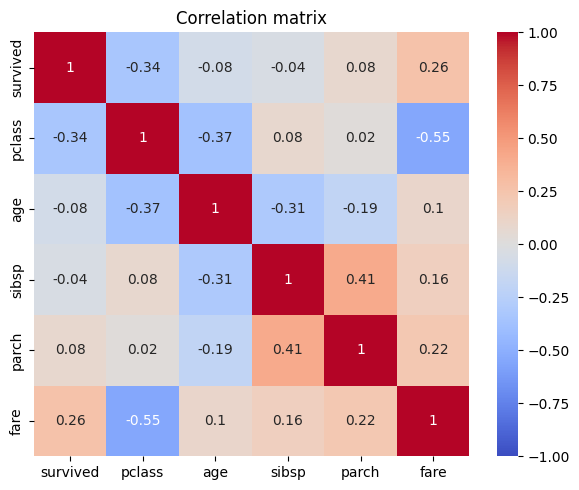

In [29]:
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix')
plt.tight_layout(); plt.show()

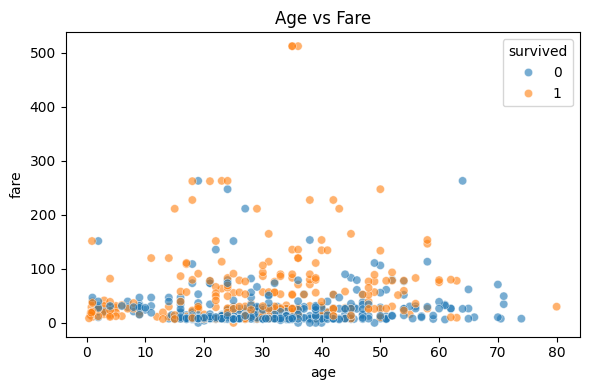

corr(age, fare) = 0.096
corr(pclass, fare) = -0.549


In [30]:
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='age', y='fare', hue='survived', alpha=0.6)
plt.title('Age vs Fare')
plt.tight_layout(); plt.show()
print("corr(age, fare) =", df['age'].corr(df['fare']).round(3))
print("corr(pclass, fare) =", df['pclass'].corr(df['fare']).round(3))

In [31]:
print("Mean fare by class:")
print(df.groupby('pclass')['fare'].mean().round(2))
print("\nMean age by class:")
print(df.groupby('pclass')['age'].mean().round(2))

Mean fare by class:
pclass
1    84.15
2    20.66
3    13.68
Name: fare, dtype: float64

Mean age by class:
pclass
1    38.23
2    29.88
3    25.14
Name: age, dtype: float64


### 5.5 Findings
See the written conclusions in the report (five findings based on the outputs above).